<a href="https://colab.research.google.com/github/dltnwjd06/2026.Linear/blob/main/202520917_%EC%9D%B4%EC%88%98%EC%A0%95_%EC%B1%8C%EB%A6%B0%EC%A7%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
%%writefile my_utils.py
import numpy as np
from matplotlib.patches import Polygon

def translate(p, dx, dy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    c, s = np.cos(theta), np.sin(theta)
    m = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def create_circle_points(num_points=30):
    """원형 부품을 만들기 위한 기본 정다각형 점들을 생성합니다."""
    angles = np.linspace(0, 2 * np.pi, num_points)
    return [np.array([np.cos(a), np.sin(a)]) for a in angles]

def draw_polygon(ax, points, color, edgecolor='black', linewidth=1.5):
    """변환된 여러 점들로 이루어진 폴리곤을 그려주는 함수"""
    my_polygon = Polygon(points, facecolor=color, edgecolor=edgecolor, linewidth=linewidth)
    ax.add_patch(my_polygon)

def draw_mouth(ax):
    """우사기 특유의 입 표현"""
    ax.plot([0, 0], [-5, -15], color='black', linewidth=2)
    ax.plot([0, -10], [-15, -5], color='black', linewidth=2)
    ax.plot([0, 10], [-15, -5], color='black', linewidth=2)

Overwriting my_utils.py


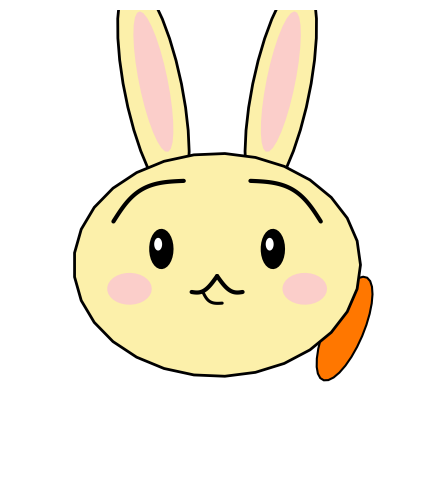

In [81]:
import importlib
import matplotlib.pyplot as plt
import my_utils
import numpy as np

# 모듈 캐시 갱신
import importlib
import my_utils

importlib.reload(my_utils)
from my_utils import (
    create_circle_points,
    draw_polygon,
    rotate,
    scale,
    translate,
)


# --- 부품별 그리기 함수 (명시적 변환 파이프라인 적용) ---


def draw_usagi_face(ax, base_circle):
  """노란색 얼굴"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 90, 70)
    q = rotate(q, 0)
    q = translate(q, 0, 0)
    points.append(q)
  draw_polygon(ax, points, '#fcf0aa', linewidth=2)


def draw_left_ear(ax, base_circle):
  """왼쪽 귀 (바깥쪽 노란색)"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 18, 70)
    q = rotate(q, 0.2)
    q = translate(q, -40, 110)
    points.append(q)
  draw_polygon(ax, points, '#fcf0aa', linewidth=2)


def draw_right_ear(ax, base_circle):
  """오른쪽 귀 (바깥쪽 노란색, y축 반전)"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, -18, 70)
    q = rotate(q, -0.2)
    q = translate(q, 40, 110)
    points.append(q)
  draw_polygon(ax, points, '#fcf0aa', linewidth=2)


def draw_left_ear_inner(ax, base_circle):
  """왼쪽 귀 안쪽 (분홍색 포인트)"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 9, 45)
    q = rotate(q, 0.2)
    q = translate(q, -40, 115)
    points.append(q)
  draw_polygon(ax, points, '#fbceca', edgecolor='none')


def draw_right_ear_inner(ax, base_circle):
  """오른쪽 귀 안쪽 (분홍색 포인트)"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, -9, 45)
    q = rotate(q, -0.2)
    q = translate(q, 40, 115)
    points.append(q)
  draw_polygon(ax, points, '#fbceca', edgecolor='none')


def draw_left_cheek(ax, base_circle):
  """왼쪽 볼터치"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 14, 10)
    q = rotate(q, 0)
    q = translate(q, -55, -15)
    points.append(q)
  draw_polygon(ax, points, '#fbceca', edgecolor='none')


def draw_right_cheek(ax, base_circle):
  """오른쪽 볼터치"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 14, 10)
    q = rotate(q, 0)
    q = translate(q, 55, -15)
    points.append(q)
  draw_polygon(ax, points, '#fbceca', edgecolor='none')


def draw_left_eye(ax, base_circle):
  """왼쪽 눈동자"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 7, 12)
    q = rotate(q, 0)
    q = translate(q, -35, 10)
    points.append(q)
  draw_polygon(ax, points, 'black')


def draw_right_eye(ax, base_circle):
  """오른쪽 눈동자"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 7, 12)
    q = rotate(q, 0)
    q = translate(q, 35, 10)
    points.append(q)
  draw_polygon(ax, points, 'black')


def draw_left_highlight(ax, base_circle):
  """왼쪽 눈 하이라이트"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 2.5, 4)
    q = rotate(q, 0)
    q = translate(q, -37, 13)
    points.append(q)
  draw_polygon(ax, points, 'white', edgecolor='none')


def draw_right_highlight(ax, base_circle):
  """오른쪽 눈 하이라이트"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 2.5, 4)
    q = rotate(q, 0)
    q = translate(q, 33, 13)
    points.append(q)
  draw_polygon(ax, points, 'white', edgecolor='none')


def draw_left_eyebrow(ax):
  """이마 위쪽으로 훨씬 높이 배치하고 크게 휜 왼쪽 눈썹"""
  t = np.linspace(0, 1, 35)
  xs_raw = -15 * (1 - t) + 15 * t
  ys_raw = 8.5 * np.sin(t * np.pi)

  tx, ty = [], []
  for px, py in zip(xs_raw, ys_raw):
    p = np.array([px, py])
    q = translate(p, 0, 0)
    q = scale(q, 1.7, 1.0)
    q = rotate(q, np.radians(30))
    q = translate(q, -43, 40.0)  # 이마 쪽으로 훨씬 높이 이동
    tx.append(q[0])
    ty.append(q[1])

  ax.plot(tx, ty, color='black', linewidth=3.0, solid_capstyle='round')


def draw_right_eyebrow(ax):
  """이마 위쪽으로 훨씬 높이 배치하고 크게 휜 오른쪽 눈썹"""
  t = np.linspace(0, 1, 35)
  xs_raw = -15 * (1 - t) + 15 * t
  ys_raw = 8.5 * np.sin(t * np.pi)

  tx, ty = [], []
  for px, py in zip(xs_raw, ys_raw):
    p = np.array([px, py])
    q = translate(p, 0, 0)
    q = scale(q, 1.7, 1.0)
    q = rotate(q, np.radians(-30))
    q = translate(q, 43, 40.0)  # 이마 쪽으로 훨씬 높이 이동
    tx.append(q[0])
    ty.append(q[1])

  ax.plot(tx, ty, color='black', linewidth=3.0, solid_capstyle='round')


def draw_usagi_mouth(ax):
  """가로 폭은 넓고, 곡률을 4.0으로 풍성하게 굴린 'ㅅ' 모양 입"""
  t = np.linspace(0, 1, 25)

  x_left = 0 * (1 - t) + (-16) * t
  y_left = (-5) * (1 - t) + (-15) * t - 4.0 * np.sin(t * np.pi)

  x_right = 0 * (1 - t) + 16 * t
  y_right = (-5) * (1 - t) + (-15) * t - 4.0 * np.sin(t * np.pi)

  def apply_pipeline(x_arr, y_arr):
    res_x, res_y = [], []
    for px, py in zip(x_arr, y_arr):
      q = translate(np.array([px, py]), 0, 0)
      q = scale(q, 1.0, 1.0)
      q = rotate(q, 0)
      q = translate(q, 0, -2)
      res_x.append(q[0])
      res_y.append(q[1])
    return res_x, res_y

  lx, ly = apply_pipeline(x_left, y_left)
  rx, ry = apply_pipeline(x_right, y_right)

  ax.plot(
      lx,
      ly,
      color='black',
      linewidth=3.0,
      solid_capstyle='round',
  )
  ax.plot(
      rx,
      ry,
      color='black',
      linewidth=3.0,
      solid_capstyle='round',
  )


def draw_usagi_lip(ax):
  """사용자 지정 아랫입술 선 (-30도 회전 및 위치 반영)"""
  t = np.linspace(0, 1, 25)

  x_start, y_start = -8.0, 0.0
  x_end, y_end = 6.0, 0.0

  xs_raw = x_start * (1 - t) + x_end * t
  ys_raw = -3 * np.sin(t * np.pi)  # 둥글게 볼록한 곡선 로컬 정의

  transformed_xs, transformed_ys = [], []
  for px, py in zip(xs_raw, ys_raw):
    p = np.array([px, py])
    q = translate(p, 0, 0)
    q = scale(q, 1.0, 1.0)
    q = rotate(q, np.radians(-30))  # 반대 방향인 -30도 회전 적용
    q = translate(q, -2, -21.0)  # 전체적으로 왼쪽 아래로 위치 이동
    transformed_xs.append(q[0])
    transformed_ys.append(q[1])

  ax.plot(
      transformed_xs,
      transformed_ys,
      color='black',
      linewidth=2.2,
      solid_capstyle='round',
  )


def draw_carrot(ax, base_circle):
  """미적 요소: 당근 오브젝트"""
  points = []
  for p in base_circle:
    q = translate(p, 0, 0)
    q = scale(q, 12, 35)
    q = rotate(q, -0.4)
    q = translate(q, 80, -40)
    points.append(q)
  draw_polygon(ax, points, '#FF7700', linewidth=1.5)


# --- 캔버스 설정 및 렌더링 ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-130, 130)
ax.set_ylim(-130, 160)
ax.set_aspect('equal')
ax.axis('off')

# 기본 원형 포인트 생성
base_circle = create_circle_points(30)

# 올바른 레이어 순서대로 렌더링
draw_left_ear(ax, base_circle)
draw_right_ear(ax, base_circle)
draw_left_ear_inner(ax, base_circle)
draw_right_ear_inner(ax, base_circle)
draw_carrot(ax, base_circle)
draw_usagi_face(ax, base_circle)
draw_left_cheek(ax, base_circle)
draw_right_cheek(ax, base_circle)
draw_left_eye(ax, base_circle)
draw_right_eye(ax, base_circle)
draw_left_highlight(ax, base_circle)
draw_right_highlight(ax, base_circle)
draw_left_eyebrow(ax)
draw_right_eyebrow(ax)
draw_usagi_mouth(ax)
draw_usagi_lip(ax)

plt.show()